In [1]:
import os##for working with file dir
import random ##create randow umber
import pandas as pd##use for manuplation and analysis
import numpy as np##working with materic and arrays
import matplotlib.pyplot as plt## to plts the graph
import seaborn as sns ###more addvance than matplotlib.pyplot
import cv2##used for various image processing tasks

In [2]:
#Set Parameters
im_width = 256
im_height = 256

In [4]:
import zipfile
zip_ref = zipfile.ZipFile(r'D:\datascience video\Datasets\DATA\archive.zip', 'r')
zip_ref.extractall(r'D:\datascience video\Datasets\DATA')
zip_ref.close()

Load image path and mask path

In [5]:
##seprate the dataon the base of mask
import glob
train_files = []
mask_files = glob.glob('D:\datascience video\Datasets\DATA/lgg-mri-segmentation/kaggle_3m/*/*_mask*')
for i in mask_files:
    train_files.append(i.replace('_mask',''))
print(train_files[:10])
print(mask_files[:10])

['D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_10.tif', 'D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_11.tif', 'D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_12.tif', 'D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_13.tif', 'D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_14.tif', 'D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_15.tif', 'D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_16.tif', 'D:\\datascience video\\Datasets\\DATA/lgg-mri-segmentation/kaggle_3m\\TCGA_CS_4941_19960909\\TCGA_CS_4941_19960909_17.tif',

Data Visualization

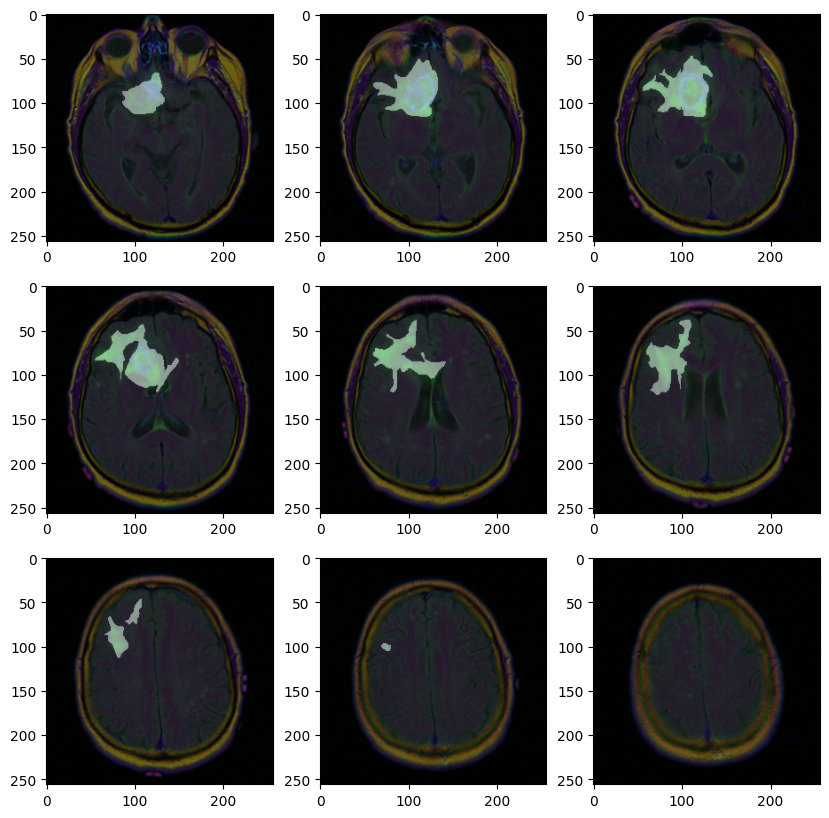

In [6]:
#create 10by10 image
fig=plt.figure(figsize=(10,10))
rows,cols=3,3
for i in range(1,rows*cols+1):#run for all the image
    fig.add_subplot(rows,cols,i)#add grid on the image
    img_path=train_files[i]#run for both dir images
    msk_path=mask_files[i]
    img=cv2.imread(img_path)#obtain file path for image and its mask
    img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)#convert image into RGB
    msk=cv2.imread(msk_path)#read mask image
    plt.imshow(img)#show image
    plt.imshow(msk,alpha=0.4)#apply 0.4 mask transparency on image
plt.show()

Create Data Frame and and split data on train set, validation set and test set

In [7]:
from sklearn.model_selection import train_test_split
df = pd.DataFrame(data={"filename": train_files, 'mask' : mask_files})
df_train, df_test = train_test_split(df,test_size = 0.1)
df_train, df_val = train_test_split(df_train,test_size = 0.2)
print(df_train.values.shape)
print(df_val.values.shape)
print(df_test.values.shape)

(2828, 2)
(708, 2)
(393, 2)


Data genertator, data augmentation and adjust data

In [8]:
import matplotlib.pyplot as plt
plt.style.use("ggplot")
%matplotlib inline

import cv2
from tqdm import tqdm_notebook, tnrange
from glob import glob
from itertools import chain
from skimage.io import imread, imshow, concatenate_images
from skimage.transform import resize
from skimage.morphology import label
from sklearn.model_selection import train_test_split

import tensorflow as tf
from skimage.color import rgb2gray
from tensorflow.keras import Input
from tensorflow.keras.models import Model, load_model, save_model
from tensorflow.keras.layers import Input, Activation, BatchNormalization, Dropout, Lambda, Conv2D, Conv2DTranspose, MaxPooling2D, concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import backend as K
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [9]:
def train_generator(data_frame, batch_size, aug_dict,
        image_color_mode="rgb",
        mask_color_mode="grayscale",
        image_save_prefix="image",
        mask_save_prefix="mask",
        save_to_dir=None,
        target_size=(256,256),
        seed=1):
    '''
    can generate image and mask at the same time use the same seed for
    image_datagen and mask_datagen to ensure the transformation for image
    and mask is the same if you want to visualize the results of generator,
    set save_to_dir = "your path"
    '''
    image_datagen = ImageDataGenerator(**aug_dict)
    mask_datagen = ImageDataGenerator(**aug_dict)

    image_generator = image_datagen.flow_from_dataframe(
        data_frame,
        x_col = "filename",
        class_mode = None,
        color_mode = image_color_mode,
        target_size = target_size,
        batch_size = batch_size,
        save_to_dir = save_to_dir,
        save_prefix  = image_save_prefix,
        seed = seed)

    mask_generator = mask_datagen.flow_from_dataframe(
        data_frame,
        x_col = "mask",
        class_mode = None,
        color_mode = mask_color_mode,
        target_size = target_size,
        batch_size = batch_size,
        save_to_dir = save_to_dir,
        save_prefix  = mask_save_prefix,
        seed = seed)

    train_gen = zip(image_generator, mask_generator)

    for (img, mask) in train_gen:
        img, mask = adjust_data(img, mask)
        yield (img,mask)

def adjust_data(img,mask):
    img = img / 255
    mask = mask / 255
    mask[mask > 0.5] = 1
    mask[mask <= 0.5] = 0

    return (img, mask)

Define loss function and metrics

In [10]:
smooth=100

def dice_coef(y_true, y_pred):
    y_truef=K.flatten(y_true)
    y_predf=K.flatten(y_pred)
    And=K.sum(y_truef* y_predf)
    return((2* And + smooth) / (K.sum(y_truef) + K.sum(y_predf) + smooth))

def dice_coef_loss(y_true, y_pred):
    return -dice_coef(y_true, y_pred)

def iou(y_true, y_pred):
    intersection = K.sum(y_true * y_pred)
    sum_ = K.sum(y_true + y_pred)
    jac = (intersection + smooth) / (sum_ - intersection + smooth)
    return jac

def jac_distance(y_true, y_pred):
    y_truef=K.flatten(y_true)
    y_predf=K.flatten(y_pred)

    return - iou(y_true, y_pred)

define unet

In [11]:
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, BatchNormalization, Activation, concatenate

def unet(input_size=(256,256,3)):
    inputs = Input(input_size)

    conv1 = Conv2D(32, (3, 3), padding='same')(inputs)
    bn1 = BatchNormalization()(conv1)
    bn1 = Activation('relu')(bn1)
    conv1 = Conv2D(32, (3, 3), padding='same')(bn1)
    bn1 = BatchNormalization()(conv1)
    bn1 = Activation('relu')(bn1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(bn1)

    conv2 = Conv2D(64, (3, 3), padding='same')(pool1)
    bn2 = BatchNormalization()(conv2)
    bn2 = Activation('relu')(bn2)
    conv2 = Conv2D(64, (3, 3), padding='same')(bn2)
    bn2 = BatchNormalization()(conv2)
    bn2 = Activation('relu')(bn2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(bn2)

    conv3 = Conv2D(128, (3, 3), padding='same')(pool2)
    bn3 = BatchNormalization()(conv3)
    bn3 = Activation('relu')(bn3)
    conv3 = Conv2D(128, (3, 3), padding='same')(bn3)
    bn3 = BatchNormalization()(conv3)
    bn3 = Activation('relu')(bn3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(bn3)

    conv4 = Conv2D(256, (3, 3), padding='same')(pool3)
    bn4 = BatchNormalization()(conv4)
    bn4 = Activation('relu')(bn4)
    conv4 = Conv2D(256, (3, 3), padding='same')(bn4)
    bn4 = BatchNormalization()(conv4)
    bn4 = Activation('relu')(bn4)
    pool4 = MaxPooling2D(pool_size=(2, 2))(bn4)

    conv5 = Conv2D(512, (3, 3), padding='same')(pool4)
    bn5 = BatchNormalization()(conv5)
    bn5 = Activation('relu')(bn5)
    conv5 = Conv2D(512, (3, 3), padding='same')(bn5)
    bn5 = BatchNormalization()(conv5)
    bn5 = Activation('relu')(bn5)
    pool5 = MaxPooling2D(pool_size=(2, 2))(bn5)

    conv6 = Conv2D(1024, (3, 3), padding='same')(pool5)
    bn6 = BatchNormalization()(conv6)
    bn6 = Activation('relu')(bn6)
    conv6 = Conv2D(1024, (3, 3), padding='same')(bn6)
    bn6 = BatchNormalization()(conv6)
    bn6 = Activation('relu')(bn6)

    up7 = concatenate([Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(bn6), conv5], axis=3)
    conv7 = Conv2D(512, (3, 3), padding='same')(up7)
    bn7 = BatchNormalization()(conv7)
    bn7 = Activation('relu')(bn7)
    conv7 = Conv2D(512, (3, 3), padding='same')(bn7)
    bn7 = BatchNormalization()(conv7)
    bn7 = Activation('relu')(bn7)

    up8 = concatenate([Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(bn7), conv4], axis=3)
    conv8 = Conv2D(256, (3, 3), padding='same')(up8)
    bn8 = BatchNormalization()(conv8)
    bn8 = Activation('relu')(bn8)
    conv8 = Conv2D(256, (3, 3), padding='same')(bn8)
    bn8 = BatchNormalization()(conv8)
    bn8 = Activation('relu')(bn8)

    up9 = concatenate([Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(bn8), conv3], axis=3)
    conv9 = Conv2D(128, (3, 3), padding='same')(up9)
    bn9 = BatchNormalization()(conv9)
    bn9 = Activation('relu')(bn9)
    conv9 = Conv2D(128, (3, 3), padding='same')(bn9)
    bn9 = BatchNormalization()(conv9)
    bn9 = Activation('relu')(bn9)

    up10 = concatenate([Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(bn9), conv2], axis=3)
    conv10 = Conv2D(64, (3, 3), padding='same')(up10)
    bn10 = BatchNormalization()(conv10)
    bn10 = Activation('relu')(bn10)
    conv10 = Conv2D(64, (3, 3), padding='same')(bn10)
    bn10 = BatchNormalization()(conv10)
    bn10 = Activation('relu')(bn10)

    up11 = concatenate([Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(bn10), conv1], axis=3)
    conv11 = Conv2D(64, (3, 3), padding='same')(up11)
    bn11 = BatchNormalization()(conv11)
    bn11 = Activation('relu')(bn11)
    conv11 = Conv2D(64, (3, 3), padding='same')(bn11)
    bn11 = BatchNormalization()(conv11)
    bn11 = Activation('relu')(bn11)

    conv12 = Conv2D(1, (1, 1), activation='sigmoid')(bn11)

    return Model(inputs=[inputs], outputs=[conv12])


In [12]:
model = unet()
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 32  896         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256, 256, 32  128        ['conv2d[0][0]']                 
 alization)                     )                                                             

Training

In [13]:
EPOCHS = 20
BATCH_SIZE = 10
learning_rate = 1e-4

In [ ]:
train_generator_args = dict(rotation_range=0.2,
                            width_shift_range=0.05,
                            height_shift_range=0.05,
                            shear_range=0.05,
                            zoom_range=0.05,
                            horizontal_flip=True,
                            fill_mode='nearest')
train_gen = train_generator(df_train, BATCH_SIZE,
                                train_generator_args,
                                target_size=(im_height, im_width))

test_gener = train_generator(df_val, BATCH_SIZE,
                                dict(),
                                target_size=(im_height, im_width))

model = unet(input_size=(im_height, im_width, 3))
decay_rate = learning_rate / EPOCHS
opt=tf.keras.optimizers.Adam(
    learning_rate=0.001,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-07,
    amsgrad=False,
    name='Adam'
)

model.compile(optimizer=opt, loss=dice_coef_loss, metrics=["binary_accuracy", iou, dice_coef])

callbacks = [ModelCheckpoint('unet_brain_mri_seg.h5', verbose=1, save_best_only=True)]

history = model.fit(train_gen,
                    steps_per_epoch=int(len(df_train) / BATCH_SIZE),
                    epochs=EPOCHS,
                    callbacks=callbacks,
                    validation_data=test_gener,
                    validation_steps=int(len(df_val) / BATCH_SIZE))


Found 2828 validated image filenames.
Found 2828 validated image filenames.
Epoch 1/20
282/282 [==============================] - ETA: 0s - loss: -0.3401 - binary_accuracy: 0.9647 - iou: 0.2349 - dice_coef: 0.3401Found 708 validated image filenames.
Found 708 validated image filenames.

Epoch 1: val_loss improved from inf to -0.03837, saving model to unet_brain_mri_seg.h5
282/282 [==============================] - 141s 439ms/step - loss: -0.3401 - binary_accuracy: 0.9647 - iou: 0.2349 - dice_coef: 0.3401 - val_loss: -0.0384 - val_binary_accuracy: 0.5051 - val_iou: 0.0198 - val_dice_coef: 0.0384
Epoch 2/20
282/282 [==============================] - ETA: 0s - loss: -0.5341 - binary_accuracy: 0.9912 - iou: 0.3984 - dice_coef: 0.5342
Epoch 2: val_loss improved from -0.03837 to -0.06854, saving model to unet_brain_mri_seg.h5
282/282 [==============================] - 83s 283ms/step - loss: -0.5341 - binary_accuracy: 0.9912 - iou: 0.3984 - dice_coef: 0.5342 - val_loss: -0.0685 - val_binary_a

In [ ]:
a = history.history

list_traindice = a['dice_coef']
list_testdice = a['val_dice_coef']

list_trainjaccard = a['iou']
list_testjaccard = a['val_iou']

list_trainloss = a['loss']
list_testloss = a['val_loss']
plt.figure(1)
plt.plot(list_testloss, 'b-')
plt.plot(list_trainloss,'r-')
plt.xlabel('iteration')
plt.ylabel('loss')
plt.title('loss graph', fontsize = 15)
plt.figure(2)
plt.plot(list_traindice, 'r-')
plt.plot(list_testdice, 'b-')
plt.xlabel('iteration')
plt.ylabel('accuracy')
plt.title('accuracy graph', fontsize = 15)
plt.show()

In [ ]:
from keras.models import load_model

model = load_model('unet_brain_mri_seg.h5', custom_objects={'dice_coef_loss': dice_coef_loss, 'iou': iou, 'dice_coef': dice_coef})


In [ ]:
test_gen = train_generator(df_test, BATCH_SIZE,
                                dict(),
                                target_size=(im_height, im_width))
results = model.evaluate(test_gen, steps=len(df_test) / BATCH_SIZE)
print("Test lost: ",results[0])
print("Test IOU: ",results[1])
print("Test Dice Coefficent: ",results[2])

In [ ]:
for i in range(30):
    index=np.random.randint(1,len(df_test.index))
    img = cv2.imread(df_test['filename'].iloc[index])
    img = cv2.resize(img ,(im_height, im_width))
    img = img / 255
    img = img[np.newaxis, :, :, :]
    pred=model.predict(img)

    plt.figure(figsize=(12,12))
    plt.subplot(1,3,1)
    plt.imshow(np.squeeze(img))
    plt.title('Original Image')
    plt.subplot(1,3,2)
    plt.imshow(np.squeeze(cv2.imread(df_test['mask'].iloc[index])))
    plt.title('Original Mask')
    plt.subplot(1,3,3)
    plt.imshow(np.squeeze(pred) > .5)
    plt.title('Prediction')
    plt.show()